# 9장. 가상계측 최적화 및 신뢰성 평가

「AI로 만드는 제조공정 품질관리 따라하기」 9장 실습 Notebook입니다.
9-1·9-2는 8장과 같은 공식 분리(training → validation+test)로,
9-3·9-4는 세 세트를 합쳐 시각 순으로 다시 나눈 운영 시뮬레이션으로 평가합니다.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/02-virtual-metrology

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_predict
from xgboost import XGBRegressor

from src.cmp_utils import (SEED, build_table, feature_columns, load_cmp, make_models,
                           regression_report, simulate_policy, time_knn_predict)

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| XGBoost", xgboost.__version__, "| Optuna", optuna.__version__)

Python 3.12.9 | scikit-learn 1.9.1 | XGBoost 3.4.1 | Optuna 5.1.0


In [3]:
data = load_cmp()
tabs = {split: build_table(*v) for split, v in data.items()}
train = tabs["train"]
train = train[train["AVG_REMOVAL_RATE"] < 1000].reset_index(drop=True)
hold = pd.concat([tabs["val"], tabs["test"]], ignore_index=True)
cols = feature_columns(train)
X, y, grp, wafer = train[cols], train["AVG_REMOVAL_RATE"].to_numpy(), train["grp"].to_numpy(), train["WAFER_ID"]
Xh, yh, grph = hold[cols], hold["AVG_REMOVAL_RATE"].to_numpy(), hold["grp"].to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, groups=wafer))
print(len(train), len(hold), len(cols))

1977 848 88


## 9-1. Optuna 기반 하이퍼파라미터 최적화

In [4]:
def cv_mae(model):
    oof = cross_val_predict(model, X, y, groups=wafer, cv=folds)
    return float(np.mean(np.abs(oof - y))), oof

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1500),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    return cv_mae(XGBRegressor(**params, random_state=SEED, n_jobs=-1))[0]

base_xgb = make_models()["XGBoost"]
base_cv, base_oof = cv_mae(base_xgb)

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
t = time.perf_counter()
study.optimize(objective, n_trials=40)
optuna_sec = time.perf_counter() - t
print(f"기본 XGBoost CV MAE {base_cv:.3f} → 최적화 CV MAE {study.best_value:.3f} ({optuna_sec:.0f}초)")
print(study.best_params)

기본 XGBoost CV MAE 2.615 → 최적화 CV MAE 2.468 (361초)
{'n_estimators': 970, 'max_depth': 7, 'learning_rate': 0.0573505757679878, 'subsample': 0.9118749304779413, 'colsample_bytree': 0.9887251833105823, 'min_child_weight': 12, 'reg_lambda': 0.010197233727414474}


In [5]:
tuned_xgb = XGBRegressor(**study.best_params, random_state=SEED, n_jobs=-1)
tuned_cv, tuned_oof = cv_mae(tuned_xgb)
compare = {}
for name, mdl, oof in [("XGBoost 기본", base_xgb, base_oof), ("XGBoost Optuna", tuned_xgb, tuned_oof)]:
    p = clone(mdl).fit(X, y).predict(Xh)
    compare[name] = {"cv_MAE": float(np.mean(np.abs(oof - y))), "hold": regression_report(yh, p, grph)}
    print(name, "| CV MAE", round(compare[name]["cv_MAE"], 3))
    print(compare[name]["hold"].round(3))

XGBoost 기본 | CV MAE 2.615
          n    MAE   RMSE     R2
전체    848.0  2.529  3.374  0.987
A123  140.0  2.615  3.409  0.264
A456  350.0  2.490  3.380  0.739
B     358.0  2.534  3.354  0.862


XGBoost Optuna | CV MAE 2.468
          n    MAE   RMSE     R2
전체    848.0  2.391  3.189  0.988
A123  140.0  2.459  3.116  0.385
A456  350.0  2.189  2.905  0.807
B     358.0  2.563  3.469  0.853


In [6]:
# 9-2 이후에 쓸 모델: CV가 더 낮은 쪽을 고른다 (평가 데이터로 고르지 않는다)
chosen_name = "XGBoost Optuna" if tuned_cv < base_cv else "XGBoost 기본"
chosen = tuned_xgb if tuned_cv < base_cv else base_xgb
chosen_oof = tuned_oof if tuned_cv < base_cv else base_oof
chosen_fit = clone(chosen).fit(X, y)
pred_h = chosen_fit.predict(Xh)
print("선택:", chosen_name)

선택: XGBoost Optuna


## 9-2. 오차 분포와 예측구간

In [7]:
# (1) Conformal: training CV 잔차의 그룹별 90% 분위수를 폭으로 쓴다
oof_res = np.abs(y - chosen_oof)
q90 = {g: float(np.quantile(oof_res[grp == g], 0.9)) for g in np.unique(grp)}
width_h = pd.Series(grph).map(q90).to_numpy()
cover_conf = np.abs(yh - pred_h) <= width_h
print("그룹별 ±폭:", {k: round(v, 2) for k, v in q90.items()})
print("평가 데이터 포함률(목표 0.90):", round(cover_conf.mean(), 3),
      {g: round(cover_conf[grph == g].mean(), 3) for g in q90})

그룹별 ±폭: {'A123': 4.61, 'A456': 4.88, 'B': 5.73}
평가 데이터 포함률(목표 0.90): 0.906 {'A123': np.float64(0.864), 'A456': np.float64(0.92), 'B': np.float64(0.908)}


In [8]:
# (2) Quantile 회귀: 5%·95% 분위수를 직접 학습한다 (웨이퍼마다 폭이 다르다)
keep = ["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "min_child_weight", "reg_lambda"]
qparams = {k: chosen.get_params()[k] for k in keep if chosen.get_params()[k] is not None}
qmodel = XGBRegressor(**qparams, objective="reg:quantileerror", quantile_alpha=np.array([0.05, 0.95]),
                      random_state=SEED, n_jobs=-1).fit(X, y)
qh = qmodel.predict(Xh)
lo, hi = np.minimum(qh[:, 0], qh[:, 1]), np.maximum(qh[:, 0], qh[:, 1])
cover_q = (yh >= lo) & (yh <= hi)
qwidth = hi - lo
print("Quantile 90% 구간 포함률:", round(cover_q.mean(), 3),
      {g: round(cover_q[grph == g].mean(), 3) for g in q90})
print("구간 폭 중앙값:", round(float(np.median(qwidth)), 2), {g: round(float(np.median(qwidth[grph == g])), 2) for g in q90})

Quantile 90% 구간 포함률: 0.542 {'A123': np.float64(0.421), 'A456': np.float64(0.56), 'B': np.float64(0.573)}
구간 폭 중앙값: 4.84 {'A123': 3.29, 'A456': 4.64, 'B': 5.33}


In [9]:
# 허용오차 가정: |오차| ≤ 5 (단위는 원본 미표기 — 실제 현장의 공정 규격으로 바꿔야 한다)
TOL = 5.0
err = np.abs(yh - pred_h)
print("허용오차 초과 비율:", round((err > TOL).mean(), 3), {g: round((err[grph == g] > TOL).mean(), 3) for g in q90})

# 신뢰 규칙 예: quantile 구간 폭이 2×TOL 이하일 때만 가상계측값을 쓰고, 넓으면 실측 요청
accept = qwidth <= 2 * TOL
print(f"가상계측 채택 {accept.mean():.3f} | 채택분 초과율 {(err[accept] > TOL).mean():.3f} | 실측 요청분 초과율 {(err[~accept] > TOL).mean():.3f}")

허용오차 초과 비율: 0.1 {'A123': np.float64(0.114), 'A456': np.float64(0.074), 'B': np.float64(0.12)}
가상계측 채택 0.988 | 채택분 초과율 0.097 | 실측 요청분 초과율 0.400


In [10]:
# (3) CQR(Conformalized Quantile Regression): quantile 구간을 training CV 결과로 보정한다
q_oof = np.zeros((len(train), 2))
for a, b in folds:
    m = clone(qmodel).fit(X.iloc[a], y[a])
    q_oof[b] = m.predict(X.iloc[b])
lo_o, hi_o = q_oof.min(1), q_oof.max(1)
score = np.maximum(lo_o - y, y - hi_o)                 # 구간 밖으로 벗어난 거리(안쪽이면 음수)
Q = float(np.quantile(score, 0.9))
lo_c, hi_c = lo - Q, hi + Q
cover_cqr = (yh >= lo_c) & (yh <= hi_c)
cwidth = hi_c - lo_c
print(f"보정량 Q = {Q:.2f} | CQR 포함률 {cover_cqr.mean():.3f}",
      {g: round(cover_cqr[grph == g].mean(), 3) for g in q90})
print("CQR 폭: 중앙값", round(float(np.median(cwidth)), 2), "| 10~90% 분위", np.round(np.quantile(cwidth, [0.1, 0.9]), 2))

accept_c = cwidth <= np.quantile(cwidth, 0.8)          # 예: 폭이 좁은 80%만 가상계측값 사용, 나머지 20% 실측 요청
print(f"CQR 규칙(폭 하위 80% 채택): 채택분 허용오차 초과율 {(err[accept_c] > TOL).mean():.3f} | 실측 요청분 {(err[~accept_c] > TOL).mean():.3f}")
rand_rate = (err > TOL).mean()
print(f"참고: 무작위로 20%를 실측할 때 채택분 초과율 기대값 {rand_rate:.3f}")

보정량 Q = 3.56 | CQR 포함률 0.907 {'A123': np.float64(0.864), 'A456': np.float64(0.929), 'B': np.float64(0.902)}
CQR 폭: 중앙값 11.96 | 10~90% 분위 [ 9.41 14.34]
CQR 규칙(폭 하위 80% 채택): 채택분 허용오차 초과율 0.087 | 실측 요청분 0.153
참고: 무작위로 20%를 실측할 때 채택분 초과율 기대값 0.100


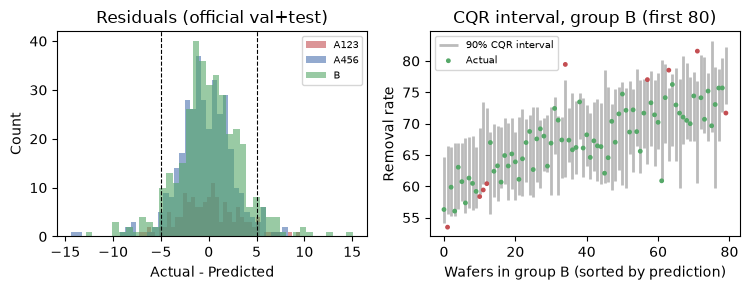

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.0))
colors = {"A123": "#C44E52", "A456": "#4C72B0", "B": "#55A868"}
for g in ["A123", "A456", "B"]:
    axes[0].hist((yh - pred_h)[grph == g], bins=40, alpha=0.6, color=colors[g], label=g)
for s in (-TOL, TOL):
    axes[0].axvline(s, color="k", ls="--", lw=0.8)
axes[0].set(xlabel="Actual - Predicted", ylabel="Count", title="Residuals (official val+test)")
axes[0].legend(fontsize=7)
order = np.argsort(pred_h[grph == "B"])[:80]
yy, pp, l2, h2 = yh[grph == "B"][order], pred_h[grph == "B"][order], lo_c[grph == "B"][order], hi_c[grph == "B"][order]
axes[1].vlines(np.arange(len(order)), l2, h2, color="#BBBBBB", lw=2, label="90% CQR interval")
axes[1].scatter(np.arange(len(order)), yy, s=6, color=np.where((yy >= l2) & (yy <= h2), "#55A868", "#C44E52"), zorder=3, label="Actual")
axes[1].set(xlabel="Wafers in group B (sorted by prediction)", ylabel="Removal rate", title="CQR interval, group B (first 80)")
axes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig("results/09_residual_interval.png", dpi=150)
plt.show()

## 9-3. 드리프트(Drift) 탐지

In [12]:
# (1) 정확도의 정체: 센서 없이 '시각이 가까운 학습 웨이퍼'만으로 예측하면?
knn_h = time_knn_predict(train, hold, k=10)
r_knn = regression_report(yh, knn_h, grph)
print("시각 kNN(센서 미사용):")
print(r_knn.round(3))
print(f"선택 모델 평가 MAE {np.mean(err):.3f} vs 시각 kNN {r_knn.loc['전체', 'MAE']:.3f}")

시각 kNN(센서 미사용):
          n    MAE   RMSE     R2
전체    848.0  2.127  2.858  0.990
A123  140.0  2.261  2.947  0.450
A456  350.0  1.907  2.608  0.845
B     358.0  2.290  3.049  0.886
선택 모델 평가 MAE 2.391 vs 시각 kNN 2.127


In [13]:
# (2) 시각 순 재분리: 세 세트를 합쳐 처음 40%로 학습, 나머지를 운영 기간으로 본다
allt = pd.concat([train, hold], ignore_index=True).sort_values("t0").reset_index(drop=True)
t_min = allt["t0"].min()
allt["day"] = (allt["t0"] - t_min) / 86400
cut = int(len(allt) * 0.4)
init, stream = allt.iloc[:cut].reset_index(drop=True), allt.iloc[cut:].reset_index(drop=True)
print(f"초기 학습 {len(init)}건 (0~{init['day'].max():.1f}일) | 운영 {len(stream)}건 (~{stream['day'].max():.1f}일)")

static = {}
for name in ["Ridge", "RandomForest", "XGBoost"]:
    static[name] = np.ravel(clone(make_models()[name]).fit(init[cols], init["AVG_REMOVAL_RATE"]).predict(stream[cols]))
static["XGBoost Optuna"] = clone(tuned_xgb).fit(init[cols], init["AVG_REMOVAL_RATE"]).predict(stream[cols])
static["GroupMean"] = stream["grp"].map(init.groupby("grp")["AVG_REMOVAL_RATE"].mean()).to_numpy()
time_rows = {n: regression_report(stream["AVG_REMOVAL_RATE"], p, stream["grp"]) for n, p in static.items()}
for n, r in time_rows.items():
    print(f"{n:15s} MAE {r.loc['전체', 'MAE']:.3f} | 그룹 내 R2 " + ", ".join(f"{g} {r.loc[g, 'R2']:.2f}" for g in ["A123", "A456", "B"]))

초기 학습 1130건 (0~28.4일) | 운영 1695건 (~65.2일)


Ridge           MAE 7.956 | 그룹 내 R2 A123 -1.29, A456 -2.54, B -2.81
RandomForest    MAE 8.594 | 그룹 내 R2 A123 -0.18, A456 -3.04, B -3.56
XGBoost         MAE 8.172 | 그룹 내 R2 A123 -1.21, A456 -2.72, B -2.75
XGBoost Optuna  MAE 7.504 | 그룹 내 R2 A123 -0.20, A456 -2.11, B -2.63
GroupMean       MAE 9.157 | 그룹 내 R2 A123 -0.71, A456 -3.16, B -3.93


In [14]:
# 입력이 학습 범위를 벗어났는가
usage = [c for c in cols if c.startswith("USAGE")]
out_range = {c: float(((stream[c] > init[c].max()) | (stream[c] < init[c].min())).mean()) for c in usage}
print("운영 기간에 학습 범위 밖인 비율:", {k: round(v, 3) for k, v in out_range.items()})
print("USAGE_OF_DRESSER_TABLE_start와 시각의 상관:", round(allt["USAGE_OF_DRESSER_TABLE_start"].corr(allt["t0"]), 3))

운영 기간에 학습 범위 밖인 비율: {'USAGE_OF_BACKING_FILM_start': 0.012, 'USAGE_OF_DRESSER_start': 0.003, 'USAGE_OF_POLISHING_TABLE_start': 0.0, 'USAGE_OF_DRESSER_TABLE_start': 1.0, 'USAGE_OF_MEMBRANE_start': 0.012, 'USAGE_OF_PRESSURIZED_SHEET_start': 0.012}
USAGE_OF_DRESSER_TABLE_start와 시각의 상관: 0.999


In [15]:
# PSI(Population Stability Index): 주 단위로 입력 분포가 학습 기간과 얼마나 다른가
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    p = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    q = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((q - p) * np.log(q / p)))

stream["week"] = ((stream["day"] - stream["day"].min()) // 7).astype(int)
watch = ["USAGE_OF_DRESSER_TABLE_start", "USAGE_OF_DRESSER_start", "SLURRY_FLOW_LINE_C_mean", "duration"]
psi_tab = pd.DataFrame({c: {w: psi(init[c], d[c]) for w, d in stream.groupby("week")} for c in watch})
weekly_mae = pd.DataFrame({n: pd.Series(np.abs(stream["AVG_REMOVAL_RATE"] - p)).groupby(stream["week"]).mean()
                           for n, p in static.items() if n in ("XGBoost", "GroupMean")})
print(psi_tab.round(2).to_string())
print(weekly_mae.round(2))

   USAGE_OF_DRESSER_TABLE_start  USAGE_OF_DRESSER_start  SLURRY_FLOW_LINE_C_mean  duration
0                         12.41                    7.58                     0.36      0.50
1                         12.41                    9.18                     0.56      1.28
2                         12.41                    3.78                     0.80      0.90
3                         12.41                    9.09                     1.49      1.38
4                         12.41                    8.96                     0.88      1.09
5                         12.41                    9.49                     2.89      5.71
      XGBoost  GroupMean
week                    
0        6.24       8.49
1        9.80       9.12
2        7.94       9.00
3        7.48       9.54
4        8.70       8.84
5       11.94      12.34


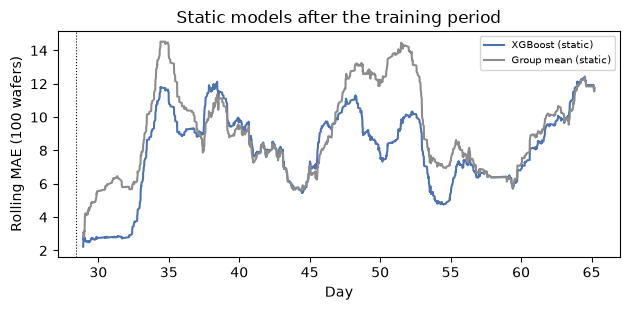

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
d = stream["day"]
roll = lambda p: pd.Series(np.abs(stream["AVG_REMOVAL_RATE"] - p)).rolling(100, min_periods=30).mean()
ax.plot(d, roll(static["XGBoost"]), label="XGBoost (static)", color="#4C72B0")
ax.plot(d, roll(static["GroupMean"]), label="Group mean (static)", color="#8C8C8C")
ax.axvline(init["day"].max(), color="k", ls=":", lw=0.8)
ax.set(xlabel="Day", ylabel="Rolling MAE (100 wafers)", title="Static models after the training period")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("results/09_drift_rolling_mae.png", dpi=150)
plt.show()

In [17]:
# 운영 기간에서 conformal 구간(학습 기간 잔차로 만든 폭)의 포함률
init_folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(init, groups=init["WAFER_ID"]))
init_oof = cross_val_predict(make_models()["XGBoost"], init[cols], init["AVG_REMOVAL_RATE"], groups=init["WAFER_ID"], cv=init_folds)
init_res = np.abs(init["AVG_REMOVAL_RATE"].to_numpy() - init_oof)
q_init = {g: float(np.quantile(init_res[init["grp"] == g], 0.9)) for g in init["grp"].unique()}
cover_stream = np.abs(stream["AVG_REMOVAL_RATE"] - static["XGBoost"]) <= stream["grp"].map(q_init)
print("운영 기간 90% 구간 포함률:", round(float(cover_stream.mean()), 3))

운영 기간 90% 구간 포함률: 0.319


## 9-4. 추가 계측 및 재학습 정책

In [18]:
LAM = 0.3          # EWMA 가중치: 미리 정한 값 (운영 결과를 보고 고르지 않는다)
init_last = init.groupby("grp")["AVG_REMOVAL_RATE"].last().to_dict()
policy_rows = []

def evaluate(name, every, pred, mode="ewma", lam=LAM):
    out, measured = simulate_policy(stream, pred, every, lam=lam, init_last=init_last, mode=mode)
    m = ~measured
    r = regression_report(stream["AVG_REMOVAL_RATE"][m], out[m], stream["grp"][m])
    policy_rows.append({"policy": name, "every": every, "measured": float(measured.mean()),
                        "MAE": r.loc["전체", "MAE"], "RMSE": r.loc["전체", "RMSE"],
                        "over_tol": float((np.abs(stream["AVG_REMOVAL_RATE"][m] - out[m]) > TOL).mean())})

for every in [2, 5, 10, 20]:
    evaluate("XGBoost 고정 (보정 없음)", every, static["XGBoost"], lam=0.0)
    evaluate("XGBoost + EWMA 보정", every, static["XGBoost"])
    evaluate("그룹 평균 + EWMA 보정", every, static["GroupMean"])
    evaluate("직전 계측값 그대로", every, static["GroupMean"], mode="last")

In [19]:
# 주 1회 재학습: 초기 학습 데이터 + 그때까지 실제로 계측한 웨이퍼만 사용
def weekly_retrain_pred(every):
    _, measured = simulate_policy(stream, np.zeros(len(stream)), every)
    pred = np.zeros(len(stream))
    for w in sorted(stream["week"].unique()):
        known = stream[(stream["week"] < w) & measured]
        fit_tab = pd.concat([init, known])
        mdl = clone(make_models()["XGBoost"]).fit(fit_tab[cols], fit_tab["AVG_REMOVAL_RATE"])
        idx = stream["week"] == w
        pred[idx.to_numpy()] = mdl.predict(stream.loc[idx, cols])
    return pred

t = time.perf_counter()
for every in [2, 5, 10, 20]:
    evaluate("XGBoost 주간 재학습 + EWMA", every, weekly_retrain_pred(every))
retrain_sec = time.perf_counter() - t
policy = pd.DataFrame(policy_rows)
print(policy.pivot(index="policy", columns="every", values="MAE").round(3))
print(policy.pivot(index="policy", columns="every", values="over_tol").round(3))
print(f"재학습 시뮬레이션 {retrain_sec:.0f}초")

every                     2      5      10     20
policy                                           
XGBoost + EWMA 보정      3.154  3.475  3.814  4.270
XGBoost 고정 (보정 없음)     8.283  8.167  8.172  8.156
XGBoost 주간 재학습 + EWMA  2.941  3.558  4.196  4.933
그룹 평균 + EWMA 보정        2.773  3.306  3.765  4.246
직전 계측값 그대로             2.798  3.262  3.778  4.497
every                     2      5      10     20
policy                                           
XGBoost + EWMA 보정      0.230  0.252  0.295  0.339
XGBoost 고정 (보정 없음)     0.689  0.677  0.678  0.674
XGBoost 주간 재학습 + EWMA  0.174  0.253  0.331  0.398
그룹 평균 + EWMA 보정        0.167  0.221  0.295  0.341
직전 계측값 그대로             0.161  0.218  0.277  0.354
재학습 시뮬레이션 18초


In [20]:
# 참고: EWMA 가중치 민감도 (정책 선택에 쓰지 않는다)
sens = {}
for lam in [0.1, 0.3, 0.6]:
    for every in [5, 20]:
        out, measured = simulate_policy(stream, static["XGBoost"], every, lam=lam)
        sens[f"lam{lam}_every{every}"] = round(float(np.mean(np.abs(stream["AVG_REMOVAL_RATE"][~measured] - out[~measured]))), 3)
print(sens)

{'lam0.1_every5': 3.866, 'lam0.1_every20': 4.802, 'lam0.3_every5': 3.475, 'lam0.3_every20': 4.27, 'lam0.6_every5': 3.408, 'lam0.6_every20': 4.199}


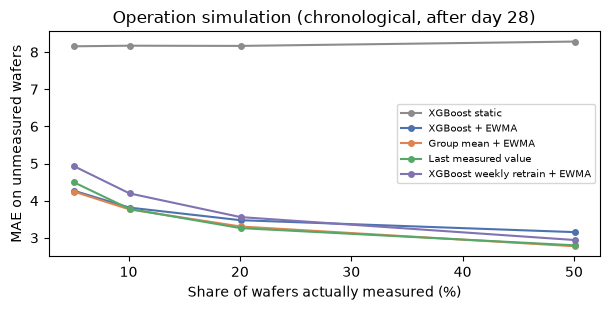

In [21]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
for name, color in [("XGBoost 고정 (보정 없음)", "#8C8C8C"), ("XGBoost + EWMA 보정", "#4C72B0"),
                    ("그룹 평균 + EWMA 보정", "#DD8452"), ("직전 계측값 그대로", "#55A868"),
                    ("XGBoost 주간 재학습 + EWMA", "#8172B2")]:
    d = policy[policy["policy"] == name]
    label = {"XGBoost 고정 (보정 없음)": "XGBoost static", "XGBoost + EWMA 보정": "XGBoost + EWMA",
             "그룹 평균 + EWMA 보정": "Group mean + EWMA", "직전 계측값 그대로": "Last measured value",
             "XGBoost 주간 재학습 + EWMA": "XGBoost weekly retrain + EWMA"}[name]
    ax.plot(d["measured"] * 100, d["MAE"], "o-", color=color, label=label, ms=4)
ax.set(xlabel="Share of wafers actually measured (%)", ylabel="MAE on unmeasured wafers",
       title="Operation simulation (chronological, after day %.0f)" % init["day"].max())
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("results/09_policy_mae.png", dpi=150)
plt.show()

In [22]:
def rep(df):
    return {k: {m: round(float(v), 3) for m, v in row.items()} for k, row in df.iterrows()}

result = {
    "optuna": {"trials": 40, "sec": round(optuna_sec, 1), "best_params": study.best_params,
               "base_cv_mae": round(base_cv, 3), "tuned_cv_mae": round(tuned_cv, 3)},
    "compare_hold": {k: {"cv_MAE": round(v["cv_MAE"], 3), "hold": rep(v["hold"])} for k, v in compare.items()},
    "chosen": chosen_name,
    "conformal_q90": {k: round(v, 2) for k, v in q90.items()},
    "conformal_cover": round(float(cover_conf.mean()), 3),
    "conformal_cover_grp": {g: round(float(cover_conf[grph == g].mean()), 3) for g in q90},
    "quantile_cover": round(float(cover_q.mean()), 3),
    "quantile_cover_grp": {g: round(float(cover_q[grph == g].mean()), 3) for g in q90},
    "quantile_width_median": round(float(np.median(qwidth)), 2),
    "cqr_Q": round(Q, 2), "cqr_cover": round(float(cover_cqr.mean()), 3),
    "cqr_cover_grp": {g: round(float(cover_cqr[grph == g].mean()), 3) for g in q90},
    "cqr_width_median": round(float(np.median(cwidth)), 2), "cqr_width_q10_q90": np.round(np.quantile(cwidth, [0.1, 0.9]), 2).tolist(),
    "cqr_rule": {"over_tol_accepted": round(float((err[accept_c] > TOL).mean()), 3), "over_tol_rejected": round(float((err[~accept_c] > TOL).mean()), 3)},
    "tol": TOL, "over_tol": round(float((err > TOL).mean()), 3),
    "over_tol_grp": {g: round(float((err[grph == g] > TOL).mean()), 3) for g in q90},
    "accept_rule": {"accept": round(float(accept.mean()), 3), "over_tol_accepted": round(float((err[accept] > TOL).mean()), 3),
                    "over_tol_rejected": round(float((err[~accept] > TOL).mean()), 3)},
    "time_knn_hold": rep(r_knn),
    "chrono": {"init_n": int(len(init)), "init_days": round(float(init["day"].max()), 1),
               "stream_n": int(len(stream)), "static": {n: rep(r) for n, r in time_rows.items()}},
    "out_of_range": {k: round(v, 3) for k, v in out_range.items()},
    "psi": psi_tab.round(2).to_dict(),
    "weekly_mae": weekly_mae.round(2).to_dict(),
    "stream_cover": round(float(cover_stream.mean()), 3),
    "policy": policy.round(3).to_dict("records"),
    "ewma_sensitivity": sens, "retrain_sec": round(retrain_sec, 1),
}
Path("results/09_reliability.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
print("저장 완료")

저장 완료
